In [10]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("../data/weather_data.csv")

df.head()

,time,temperature_2m,relative_humidity_2m,pressure_msl,wind_speed_10m,wind_direction_10m
0,2026-03-01T00:00,25.6,86,1008.8,8.7,339
1,2026-03-01T01:00,25.2,87,1008.4,6.4,331
2,2026-03-01T02:00,24.7,88,1007.7,6.5,328
3,2026-03-01T03:00,24.1,91,1007.7,6.1,346
4,2026-03-01T04:00,23.3,94,1007.8,3.3,347


In [2]:
df.shape

(4416, 6)

In [3]:
df.isnull().sum()

time                    0
temperature_2m          0
relative_humidity_2m    0
pressure_msl            0
wind_speed_10m          0
wind_direction_10m      0
dtype: int64

In [6]:
df["wind_speed_10m"].describe()

count    4416.000000
mean        7.429348
std         4.712473
min         0.000000
25%         3.500000
50%         6.500000
75%        10.700000
max        22.900000
Name: wind_speed_10m, dtype: float64

In [7]:
df["time"] = pd.to_datetime(df["time"])
df["hour"] = df["time"].dt.hour

df.head()

,time,temperature_2m,relative_humidity_2m,pressure_msl,wind_speed_10m,wind_direction_10m,hour
0,2026-03-01 00:00:00,25.6,86,1008.8,8.7,339,0
1,2026-03-01 01:00:00,25.2,87,1008.4,6.4,331,1
2,2026-03-01 02:00:00,24.7,88,1007.7,6.5,328,2
3,2026-03-01 03:00:00,24.1,91,1007.7,6.1,346,3
4,2026-03-01 04:00:00,23.3,94,1007.8,3.3,347,4


In [8]:
hourly_wind = df.groupby("hour")["wind_speed_10m"].mean()

hourly_wind

hour
0      5.320109
1      5.017391
2      4.682065
3      4.261413
4      4.460870
5      5.397826
6      4.942391
7      4.955435
8      4.777717
9      5.221196
10     6.854348
11     8.897826
12    11.591848
13    12.843478
14    13.285870
15    13.134783
16    12.550543
17    10.632609
18     8.885870
19     7.584239
20     6.453261
21     5.419565
22     5.345109
23     5.788587
Name: wind_speed_10m, dtype: float64

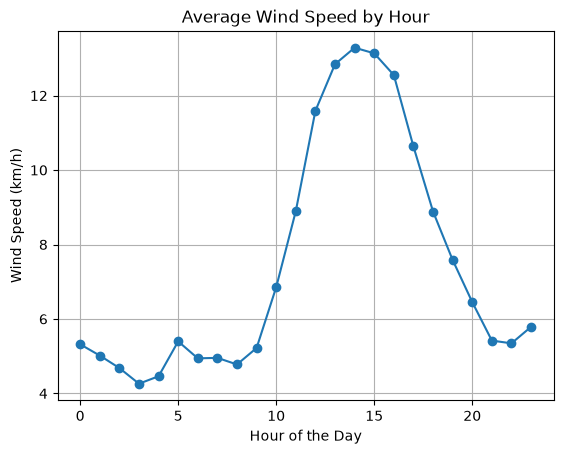

In [11]:
hourly_wind.plot(
    kind="line",
    marker="o",
    title="Average Wind Speed by Hour"
)

plt.xlabel("Hour of the Day")
plt.ylabel("Wind Speed (km/h)")
plt.grid()
plt.show()

In [12]:
print("Strongest wind hour:", hourly_wind.idxmax())
print("Weakest wind hour:", hourly_wind.idxmin())

Strongest wind hour: 14
Weakest wind hour: 3
